#### Config and models

In [1]:
import os 
from collections import deque
from pathlib import Path

import cv2 
import gdown
import numpy as np
import supervision as sv
from dotenv import load_dotenv, find_dotenv
from inference import get_model
from sports.annotators.soccer import draw_pitch, draw_points_on_pitch
from sports.common.team import TeamClassifier
from sports.configs.soccer import SoccerPitchConfiguration
from tqdm import tqdm

load_dotenv(find_dotenv(usecwd=True))
API_KEY = os.getenv("ROBOFLOW_API_KEY")

PLAYER_MODEL_ID = "ali-sherifzade-s-workspace/football-players-detection-3zvbc-m8uiw-1-yolov8m-t1"
FIELD_MODEL_ID = "football-field-detection-f07vi/14"

BALL, GK, PLAYER, REF = 0, 1, 2 , 3
CONF = 0.3
STRIDE = 30
DEVICE = "cpu"

VIDEOS = {
    "0bfacc_0.mp4": "12TqauVZ9tLAv8kWxTTBFWtgt2hNQ4_ZF",
    "2e57b9_0.mp4": "19PGw55V8aA6GZu5-Aac5_9mCy3fNxmEf",
    "08fd33_0.mp4": "1OG8K6wqUw9t7lp9ms1M48DxRhwTYciK-",
    "573e61_0.mp4": "1yYPKuXbHsCxqjA9G-S6aeR2Kcnos8RPU",
    "121364_0.mp4": "1vVwjW1dE1drIdd4ZSILfbCGPD4weoNiu",
}

VIDEO = "data/videos/121364_0.mp4"

PLAYER_MODEL = get_model(PLAYER_MODEL_ID, api_key= API_KEY)
FIELD_MODEL = get_model(FIELD_MODEL_ID, api_key=API_KEY)
PITCH = SoccerPitchConfiguration()

c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\inference\core\env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(


[10/17/26 18:51:28] WARNING  Your inference package version 1.7.4 is out of date! Please upgrade to  __init__.py:88
                             version 1.8.0 of inference for the latest features and bug fixes by                   
                             running `pip install --upgrade inference`.                                            

c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\inference\models\utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Use pip install 'inference[sam]' to install missing requirements.To suppress this warning, set CORE_MODEL_SAM_ENABLED to False.
  warnings.warn(
c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\inference\models\utils.py:597: ModelDependencyMissing: Your `inference` configuration does not support SAM3 model. Install SAM3 dependencies and set CORE_MODEL_SAM3_ENABLED to True.
  warnings.warn(
[transformers] `DepthProImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `DepthProImageProcessor` instead.
c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__}

### Download videos

In [2]:
Path("data/videos").mkdir(parents=True, exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

for name, fid in VIDEOS.items():
    dest = Path("data/videos") / name
    if not dest.exists():
        gdown.download(id=fid, output = str(dest), quiet=False)

### Preview raw detections

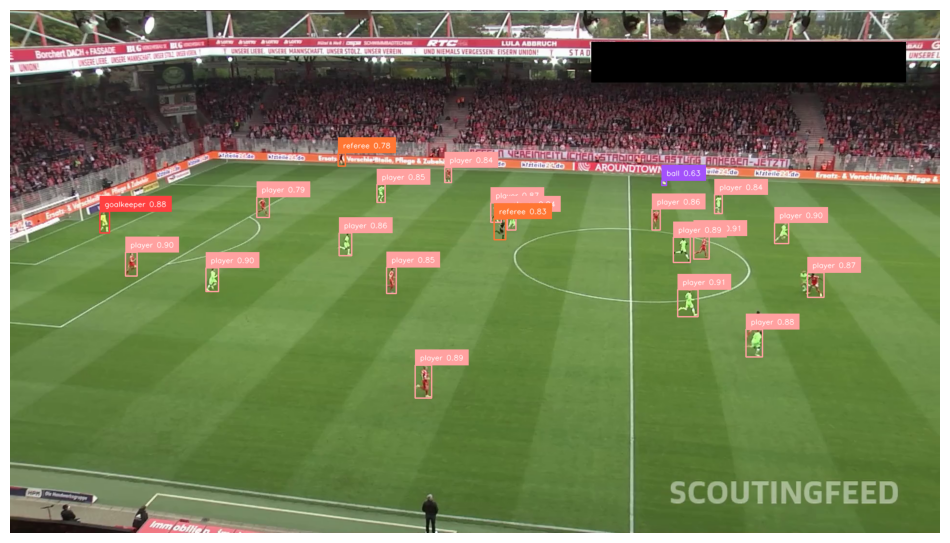

In [3]:
frame = next(sv.get_video_frames_generator(VIDEO))
result = PLAYER_MODEL.infer(frame, confidence=CONF)[0]
det = sv.Detections.from_inference(result)

labels = [f"{n} {c:.2f}" for n, c in zip(det["class_name"], det.confidence)]
img = sv.BoxAnnotator().annotate(frame.copy(), det)
img = sv.LabelAnnotator().annotate(img, det, labels=labels)
sv.plot_image(img)

### Team Classifier

In [4]:
crops = []
for f in tqdm(sv.get_video_frames_generator(VIDEO, stride=STRIDE), desc="crops"):
    d = sv.Detections.from_inference(PLAYER_MODEL.infer(f, confidence=CONF)[0])
    d = d.with_nms(0.5, class_agnostic=True)
    d = d[d.class_id == PLAYER]
    crops += [sv.crop_image (f , xyxy) for xyxy in d.xyxy]

team_classifier = TeamClassifier(device=DEVICE)
team_classifier.fit(crops)

crops: 25it [02:08,  5.14s/it]
Loading weights: 100%|██████████| 208/208 [00:00<00:00, 16080.79it/s]
Embedding extraction: 16it [03:12, 12.01s/it]


### Pipeline function

In [10]:
PALETTE = sv.ColorPalette.from_hex(["#00BFFF", "#FF1493", "#FFD700"])
ellipse = sv.EllipseAnnotator(color=PALETTE, thickness=2)
label = sv.LabelAnnotator(color=PALETTE, text_color=sv.Color.BLACK,
                          text_position=sv.Position.BOTTOM_CENTER)
triangle = sv.TriangleAnnotator(color=sv.Color.from_hex("#FFD700"), base=20, height=17)

tracker = sv.ByteTrack()
Ms = deque(maxlen=5)

def goalkeeper_teams(players, gks):
    gk_xy = gks.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
    pl_xy = players.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
    c0 = pl_xy[players.class_id == 0].mean(axis=0)
    c1 = pl_xy[players.class_id == 1].mean(axis=0)
    return np.array([0 if np.linalg.norm(g-c0) < np.linalg.norm(g-c1) else 1 for g in gk_xy])


def to_pitch(det):
    pts = det.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
    if len(pts) == 0 or not Ms:
        return np.empty((0,2))
    m = np.mean (Ms, axis=0)
    return cv2.perspectiveTransform(pts.reshape(-1,1,2).astype(np.float32), m).reshape(-1,2)


def process(frame):
    det = sv.Detections.from_inference(PLAYER_MODEL.infer(frame, confidence=CONF)[0])
    ball = det[det.class_id == BALL]
    ball.xyxy = sv.pad_boxes(xyxy = ball.xyxy, px=10)
    
    rest = det[det.class_id != BALL].with_nms(0.5, class_agnostic=True)
    gk, pl, ref = (rest[rest.class_id == i] for i in (GK, PLAYER, REF))
    
    if len(pl):
        pl.class_id = team_classifier.predict([sv.crop_image(frame,b)for b in pl.xyxy])
    if len(gk) and len(pl):
        gk.class_id = goalkeeper_teams(pl,gk)
    ref.class_id = np.full(len(ref), 2)
    
    allp = sv.Detections.merge([pl, gk, ref])
    allp.class_id = allp.class_id.astype(int)
    
    out = ellipse.annotate(frame.copy(), allp)
    if len(allp) and allp.tracker_id is not None:
        out = label.annotate(out, allp, labels=[f"#{t}" for t in allp.tracker_id])
    out = triangle.annotate(out, ball)
    
    # Homography 
    kp = sv.KeyPoints.from_inference(FIELD_MODEL.infer(frame, confidence=CONF)[0])
    mask = kp.confidence[0] > 0.5
    if mask.sum() >= 4:
        m, _ = cv2.findHomography(kp.xy[0][mask].astype(np.float32),
                                  np.array(PITCH.vertices)[mask].astype(np.float32))
        if m is not None:
            Ms.append(m)
    
    # Radar
    pp = sv.Detections.merge([pl, gk])
    xy = to_pitch(pp)
    radar = draw_pitch(PITCH)
    radar = draw_points_on_pitch(PITCH,  to_pitch(ball), sv.Color.WHITE, sv.Color.BLACK, 10, pitch=radar)
    
    for tid, col in ((0, "00BFFF"),(1, "FF1493")):
        radar = draw_points_on_pitch(PITCH, xy[pp.class_id == tid] if len(xy) else xy,
                                     sv.Color.from_hex(col), sv.Color.BLACK, 16, pitch=radar)
    radar =  draw_points_on_pitch(PITCH,  to_pitch(ref), sv.Color.from_hex("FFD700"),
                                                                           sv.Color.BLACK, 16, pitch=radar)
    
    return out, radar

### Preview a frame

Embedding extraction: 1it [00:03,  3.15s/it]
c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\supervision\key_points\core.py:308: SupervisionWarnings: 'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.
  warn_deprecated(


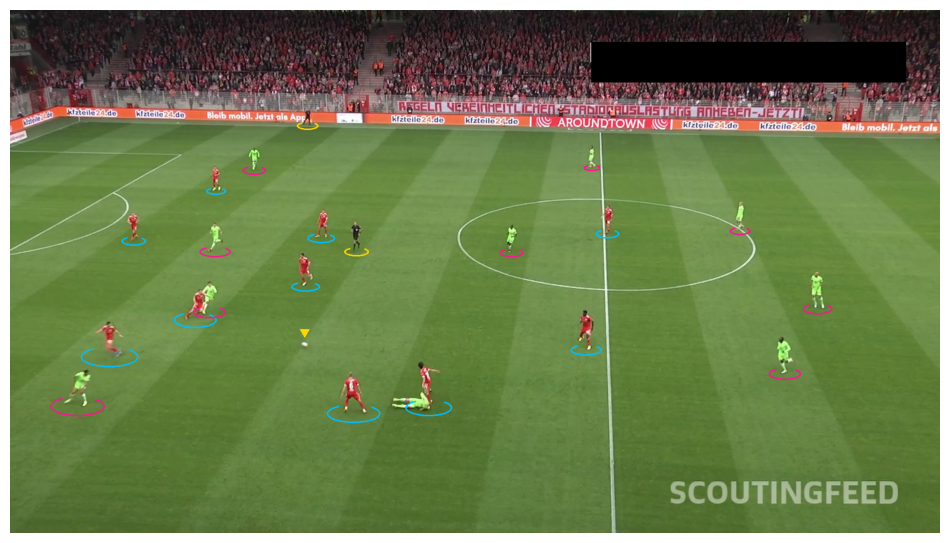

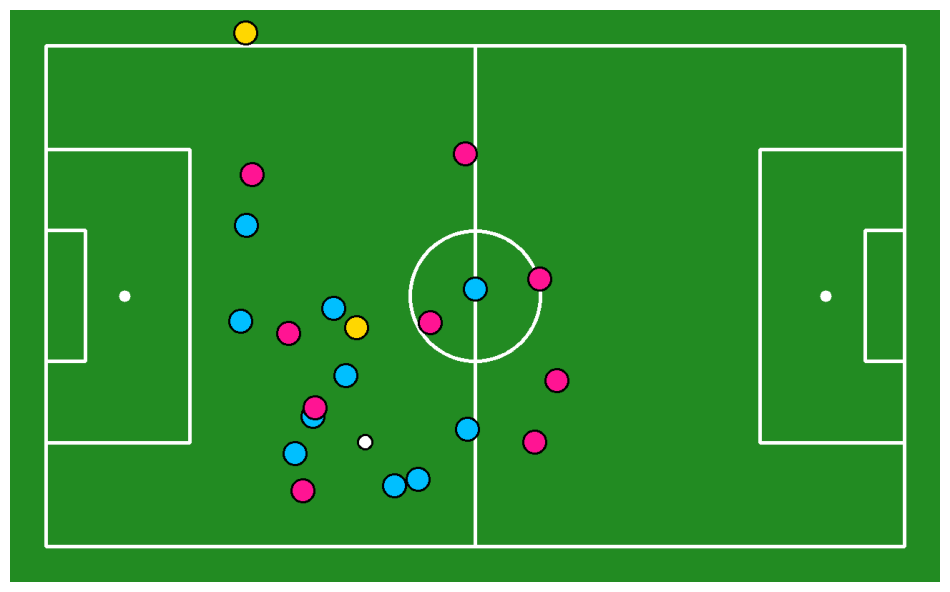

In [11]:
tracker.reset(); Ms.clear()
frame = next(sv.get_video_frames_generator(VIDEO, start=200))
annotated, radar = process(frame)
sv.plot_image(annotated)
sv.plot_image(radar)


### Full Video

In [12]:
tracker.reset(); Ms.clear()
info = sv.VideoInfo.from_video_path(VIDEO)
radar_writer = None

with sv.VideoSink("outputs/annotated.mp4", info) as sink:
    for frame in tqdm(sv.get_video_frames_generator(VIDEO), total=info.total_frames):
        out, radar = process(frame)
        sink.write_frame(out)
        if radar_writer is None:
            h, w = radar.shape[:2]
            radar_writer = cv2.VideoWriter("outputs/radar.mp4",
                                           cv2.VideoWriter_fourcc(*"mp4v"), info.fps, (w, h))
        radar_writer.write(radar)

radar_writer.release()

  0%|          | 0/750 [00:00<?, ?it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:02,  2.91s/it]
c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\supervision\key_points\core.py:308: SupervisionWarnings: 'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.
  warn_deprecated(
  0%|          | 1/750 [00:05<1:05:05,  5.21s/it]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:02,  2.82s/it]
c:\Users\Sharif\Desktop\Football Computer Vison\.venv\Lib\site-packages\supervision\key_points\core.py:308: SupervisionWarnings: 'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.
  warn_deprecated(
  0%|          | 2/750 [00:10<1:03:20,  5.08s/it]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:02,  3.00s/it]
c:\Users\Sharif\Desktop\Football Computer Vison\.venv\